# Introduction to AI: Machine Learning for Business - Final project

## Context

Congratulations, you’ve just been hired as an AI expert at a company.

For this final project you are required to choose and define a business problem to which you will apply machine learning.<br>
Your final submission should include the following:

- Problem definition
- Data Collection
- Data Processing
- Model Selection
- Results Visualization
- Results Interpretation

## Your dataset

The group should select a real life dataset.<br>
Finding an appropriate dataset is part of the game and will determine the quality of your work.<br>
**It requires spending a significant amount of time doing research.**

The selected dataset should contain at least 15 columns and at least 30000 rows.

## What should you do ?

Make a notebook telling interesting things about the data you have fetched, tell a story (or many) using everything you learned. Build predictive models and compare them.<br>
You have to submit at least a notebook and any resources you used (like images or any other files).

## Assessment
Here are the criteria we will use to assess your work:

#### Is it meaningful?
As a machine learning expert you have to produce something meaningful enough, just plotting random data is not going to work.<br>
Like a story your analysis should have some kind of logical progression.

#### How well did you use the technical knowledge you’ve been taught?
Obviously, the way you use everything you learned during the lectures is going to be assessed.

#### Cleanliness, aesthetics and clarity of your notebook
Is your analysis full of unused code? Is it difficult to read? Have you tried to make it easy and enjoyable to read?

#### Innovation
Creativity, surprising things or any good initiatives you take are potential bonus points.

#### Accountability & Presentation
You will present your group work in a final presentation
- You will be assessed as a group, based on your notebook and your ppt (or equivalent) presentation
- You will be assessed individually on your oral presentation
- It must be stated in your document, who did what

### `Careful:`
**`This work is unique to each group, plagiarism is going to be measured by both machines and humans. Too many similarities between your work and any online or python buddy work will result in grade penalties.`**


**Good Luck!**


#Problem Definition

There are several reasons why predicting salaries can be valuable.

First, from an HR perspective, companies need to determine appropriate compensation for future employees or respond to candidates’ salary expectations. On the other hand, candidates themselves may want to better understand their market value in order to negotiate their salary more effectively.

Beyond recruitment, salary prediction can also be useful for broader purposes such as cost analysis, company benchmarking, market analysis, or even conducting social and economic studies on compensation trends.

Based on the dataset available, the objective of this project is to build a model capable of predicting a reliable salary estimate. This task is therefore formulated as a numerical regression problem.

Such a model could help organizations make data-driven compensation decisions and improve fairness and competitiveness in the job market. Different machine learning models will be implemented and compared to identify the most effective approach.


# Data Collection

We selected our dataset from Kaggle. It contains approximately 250,000 rows and 10 columns.

The dataset is composed of:

### Numerical variables:
- experience_years  
- skills_count  
- certifications  
- salary  

### Categorical variables:
- job_title → **job_group (modified)**  
- education_level  
- industry  
- company_size  
- location → **location (modified)**  
- remote_work  

---

## Feature Engineering

To improve the quality of our analysis and reduce dimensionality (especially for encoding purposes), we performed feature engineering on some categorical variables.

### Job Title Grouping

The original `job_title` column contained many similar roles with slight variations. To simplify the dataset and improve model performance, we grouped similar job titles into broader categories:

- **Data** → Data Scientist, Data Analyst, etc.  
- **AI/ML** → AI Engineer, Machine Learning Engineer  
- **Engineering** → Backend Developer, Frontend Developer, Software Engineer  
- **Cloud/DevOps** → DevOps Engineer, Cloud Engineer  
- **Business** → Product Manager, Business Analyst  
- **Security** → Cybersecurity Analyst  
- **Other** → all remaining roles  

This transformation reduces the number of categories and helps prevent the curse of dimensionality when applying encoding techniques.

---

### Location Grouping

The `location` column was also transformed to reduce the number of unique values and make the data more interpretable.

We grouped countries into broader geographical regions:

- **North America** → USA, Canada  
- **Europe** → UK, Germany, Netherlands, Sweden  
- **Asia** → India, Singapore  
- **Oceania** → Australia  
- **Remote** → Remote jobs  
- **Other** → all remaining locations  

This grouping helps simplify the dataset and improves model generalization by reducing noise from less frequent categories.

---

These transformations allow for a more efficient encoding process and contribute to better model performance.

In [1]:

#Visulaisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

import warnings
warnings.filterwarnings("ignore")

#Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

#Evaluation Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error  # sklearn >= 1.4, sinon np.sqrt(mse)
)

#Linear regression
from sklearn.linear_model import LinearRegression

#Rdge  Lasso
from sklearn.linear_model import Ridge, Lasso, ElasticNet

#decisiontree
from sklearn.tree import DecisionTreeRegressor

#RandomForest
from sklearn.ensemble import RandomForestRegressor

#Xgboost
from xgboost import XGBRegressor



Data Collection

In [2]:

uploaded = files.upload()

df_salary = pd.read_csv("job_salary_prediction_dataset_final.csv")

df_salary.head()

Saving job_salary_prediction_dataset_final.csv to job_salary_prediction_dataset_final.csv


,job_group,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI/ML,10,Bachelor,2,Healthcare,Medium,Asia,Hybrid,2,109413
1,Data,5,Bachelor,17,Telecom,Small,Oceania,No,0,93764
2,Engineering,18,PhD,4,Media,Medium,Asia,No,1,148123
3,Business,19,PhD,13,Retail,Medium,North America,Yes,0,189123
4,Business,15,Bachelor,7,Manufacturing,Large,Europe,Yes,0,165069


In [ ]:
df_salary.describe().round(1)

# Exploratory Data Analysis

1.   List item
2.   List item



The goal of this section is to have a better understanding of the dataset, identify the eventual patterns, explore relationships between variables, especially with out target output variable : salary.

In [ ]:
cat_columns = df_salary.select_dtypes(include = "object").columns
num_columns = df_salary.select_dtypes(include = "number").columns

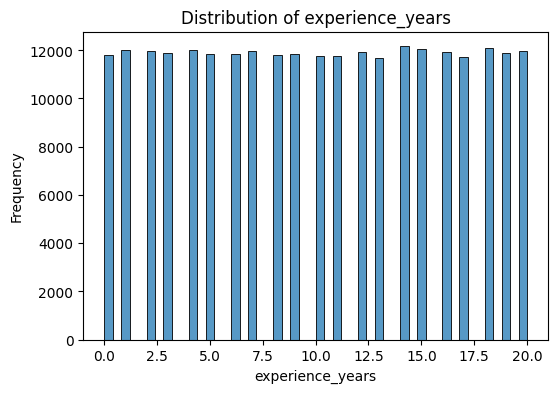

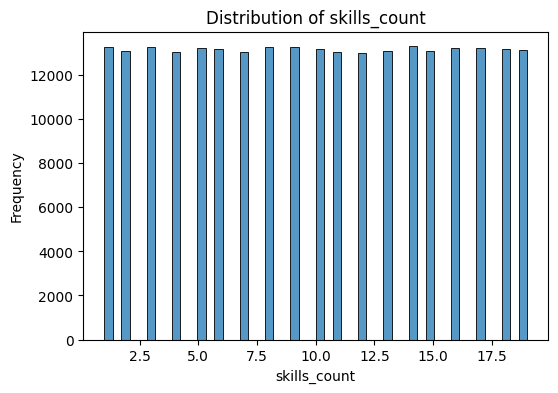

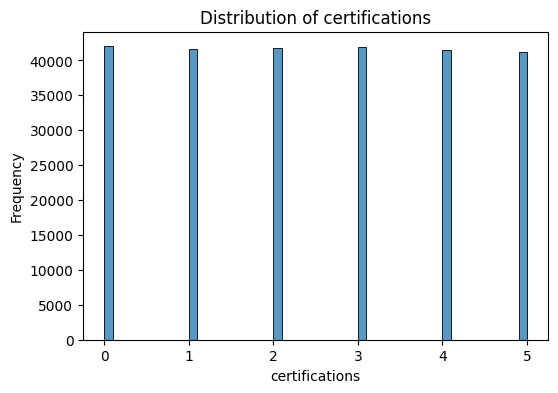

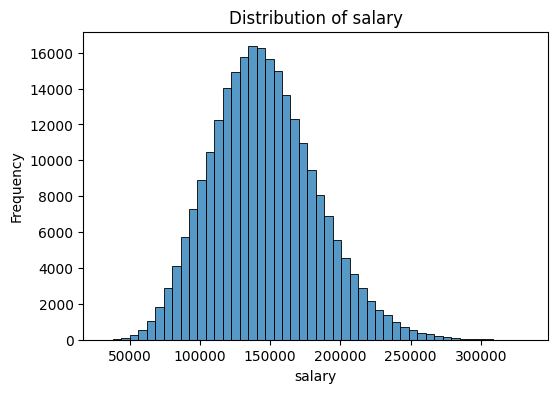

In [ ]:
for col in num_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df_salary[col], bins=50)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

### Numerical Variables Analysis

The numerical variables in the dataset are well distributed overall.

- The salary distribution follows a near-normal (Gaussian) distribution, indicating a balanced spread of values without strong skewness.
- Experience years are also evenly distributed, suggesting a good representation of both junior and senior profiles.
- Skills count and certifications show consistent distributions, with no major concentration or imbalance.

Overall, the numerical features present a well-balanced structure, which is beneficial for model training and reduces the risk of bias.

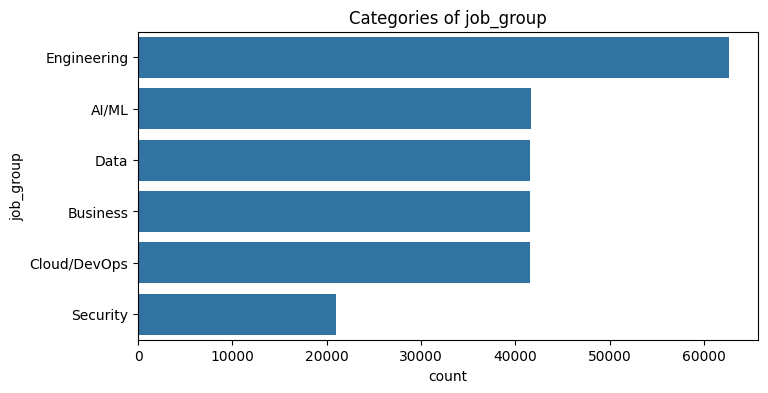

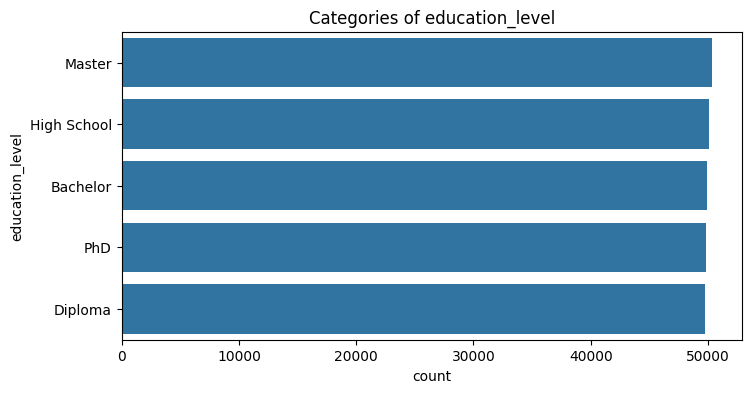

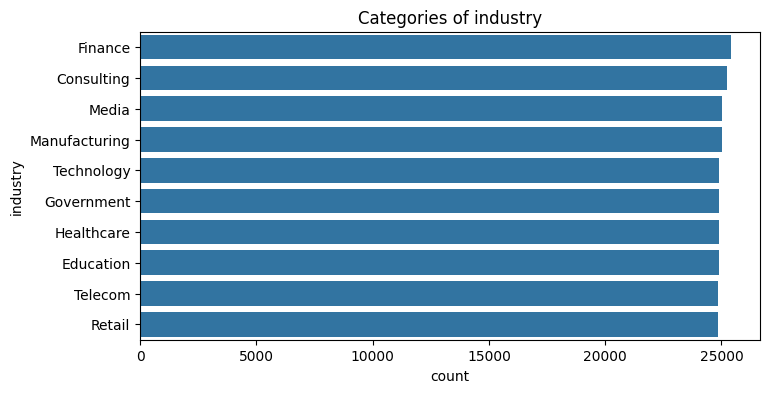

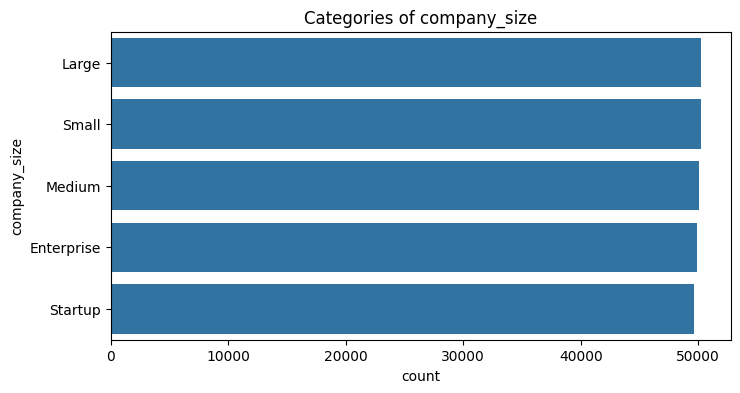

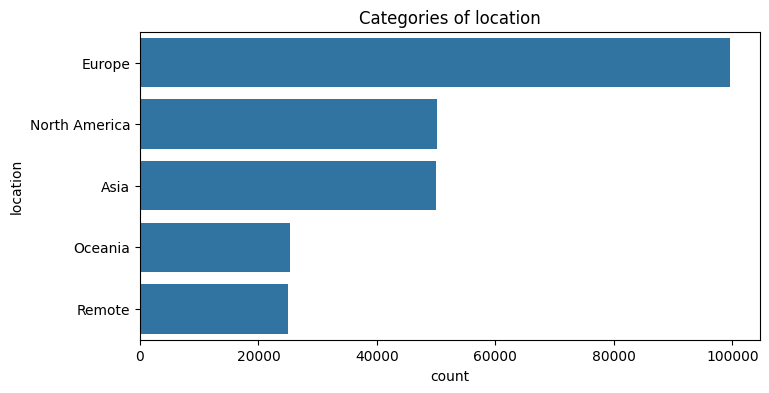

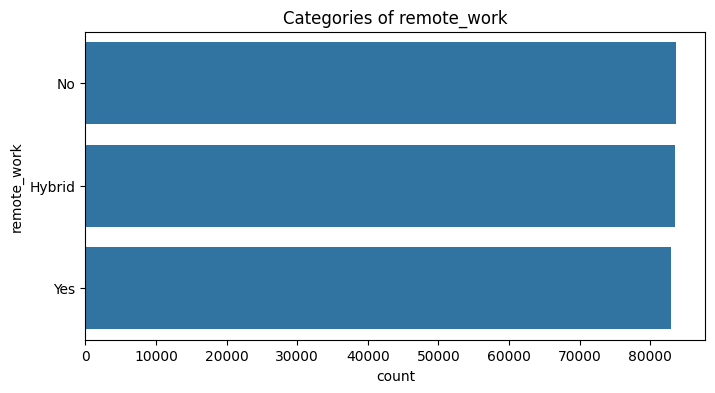

In [ ]:
for col in cat_columns:
    plt.figure(figsize=(8,4))
    top_values = df_salary[col].value_counts().index
    sns.countplot(data=df_salary, y=col, order=top_values)
    plt.title(f"Categories of {col}")
    plt.show()

### Categorical Variables Analysis

The categorical variables are generally well balanced across categories.

- For job groups, there is a slightly higher representation of Engineering roles compared to other categories. Security roles are less represented, but still account for around 20,000 observations, which remains sufficient for analysis.
- Regarding location, Europe is more represented than other regions, while Oceania and Remote positions are less frequent. However, these categories still contain enough data to remain meaningful.

Overall, the distribution across categorical variables is satisfactory and does not raise major concerns regarding imbalance.

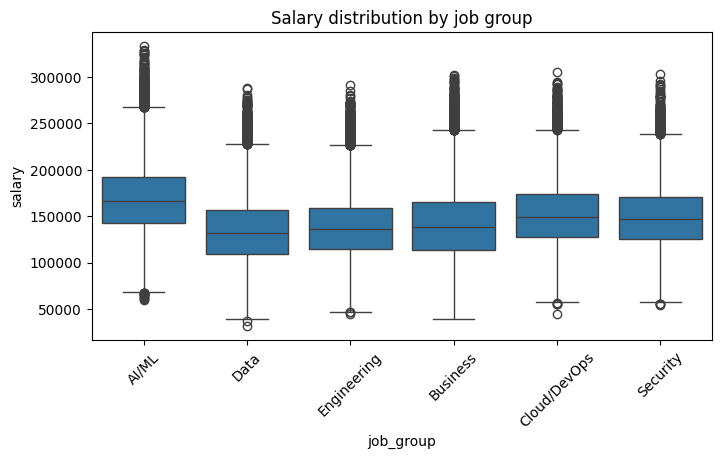

In [ ]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df_salary, x="job_group", y="salary")
plt.xticks(rotation=45)
plt.title("Salary distribution by job group")
plt.show()

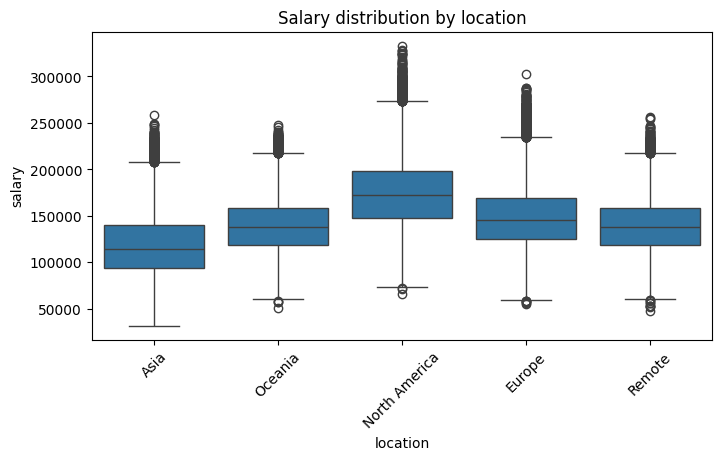

In [ ]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df_salary, x="location", y="salary")
plt.xticks(rotation=45)
plt.title("Salary distribution by location")
plt.show()

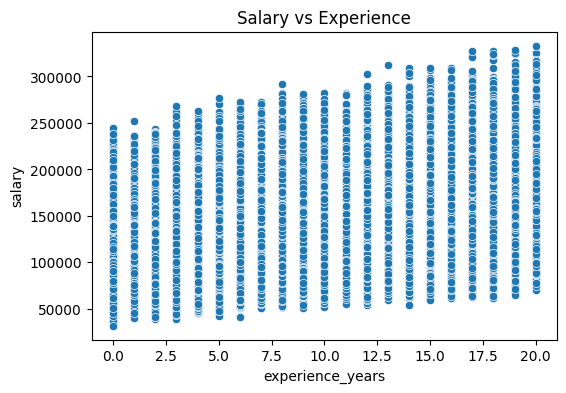

In [ ]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df_salary, x="experience_years", y="salary")
plt.title("Salary vs Experience")
plt.show()

### Relationship with Salary

Several interesting patterns emerge when analyzing the relationship between features and salary:

- **Job Group**: AI/ML roles tend to have higher salaries compared to other job categories, confirming the high demand and specialization required for these positions.
- **Location**: Salaries are generally higher in North America, followed by Europe, while other regions show relatively similar salary levels.
- **Experience**: There is a clear positive relationship between experience and salary. As expected, salaries increase with the number of years of experience.

These findings are consistent with real-world labor market trends.

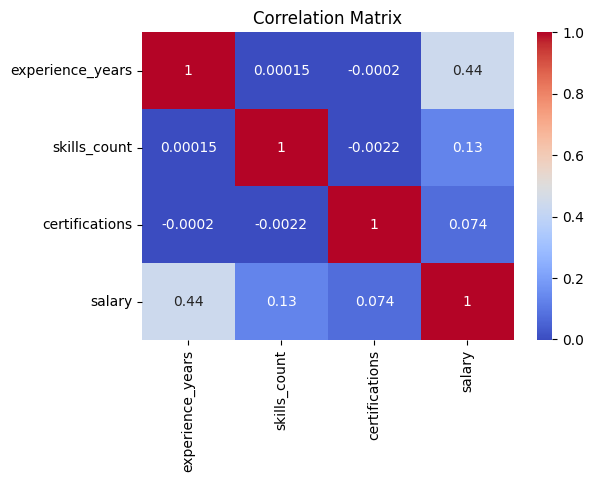

In [ ]:
plt.figure(figsize=(6,4))
sns.heatmap(df_salary[num_columns].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

### Correlation Analysis

The correlation matrix reveals relatively weak linear relationships between most variables and salary.

- The strongest correlation is observed between **experience_years and salary** (~0.44), indicating a moderate positive relationship.
- **Skills_count and salary** show a weaker correlation (~0.13).
- All other variables have correlations close to zero, suggesting little to no linear relationship with salary.

This suggests that salary prediction may rely on a combination of features rather than a single strong predictor, and that non-linear models may perform better.

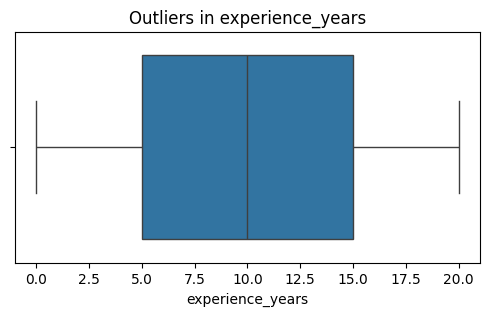

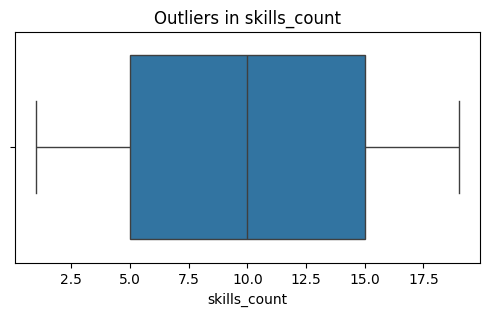

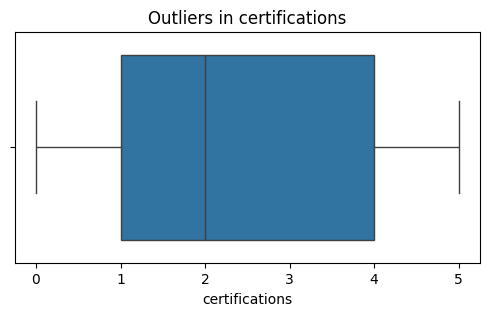

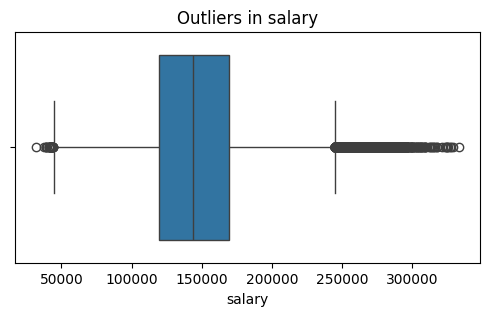

In [ ]:
for col in num_columns:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df_salary[col])
    plt.title(f"Outliers in {col}")
    plt.show()

### Outliers Analysis

Outliers are mainly observed in the salary variable. The boxplot shows several extreme values on both ends, indicating the presence of unusually high (and possibly low) salaries.

This is expected in real-world data, as some positions—especially in specialized or high-demand fields—can offer significantly higher compensation. These outliers may represent genuine cases rather than data errors, but they should be considered carefully as they can influence model performance.



# Data Preprocessing

In this section, we prepare the dataset for machine learning models. This includes data cleaning, encoding categorical variables, feature scaling, and splitting the dataset into training and testing sets.

---

## Data Cleaning

Before applying any transformations, let's check the presence of any missing values or duplicates.


In [ ]:
#Missing values
print(df_salary.isna().sum())

#Duplicates
print(df_salary.duplicated().sum())

job_group           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64
0


Good News. Neither duplicated nor missing values. We will not clean the dataset, it's already done !



---

### Feature Engineering

Feature engineering has already been performed prior to this step.

- The `job_title` column was transformed into `job_group`
- The `location` column was transformed into `location_group`

These transformations help reduce dimensionality and improve model performance.
See above for more info.

---

### Encoding Categorical Variables

Since most machine learning models require numerical input, categorical variables need to be encoded.

We will use **One-Hot Encoding (OHE)** because:
- there is no ordinal relationship between categories
- it avoids introducing artificial ranking between categories


In [ ]:
df_encoded = pd.get_dummies(df_salary, drop_first=True)
df_encoded.head()

,experience_years,skills_count,certifications,salary,job_group_Business,job_group_Cloud/DevOps,job_group_Data,job_group_Engineering,job_group_Security,education_level_Diploma,...,company_size_Large,company_size_Medium,company_size_Small,company_size_Startup,location_Europe,location_North America,location_Oceania,location_Remote,remote_work_No,remote_work_Yes
0,10,2,2,109413,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
1,5,17,0,93764,False,False,True,False,False,False,...,False,False,True,False,False,False,True,False,True,False
2,18,4,1,148123,False,False,False,True,False,False,...,False,True,False,False,False,False,False,False,True,False
3,19,13,0,189123,True,False,False,False,False,False,...,False,True,False,False,False,True,False,False,False,True
4,15,7,0,165069,True,False,False,False,False,False,...,True,False,False,False,True,False,False,False,False,True


In [ ]:
df_salary.shape

(250000, 10)

In [ ]:
df_encoded.shape

(250000, 32)

We've created 22 new columns :  the fetaure enginnering step was necessary to avoid having too much columns. We already have many

---

### Feature Scaling

Feature scaling is applied to numerical variables to ensure that all features are on the same scale. This is particularly important for linear models such as Linear Regression, Ridge, and Lasso.

We use **Standardization (StandardScaler)**, which transforms the data to have a mean of 0 and a standard deviation of 1.


In [ ]:
scaler = StandardScaler()

X = df_encoded.drop("salary", axis=1)
y = df_encoded["salary"]

X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

#Model Selection and Training

##Linear Regression
Let's begin with a simple but very famous model :  the Linear Regression. The model learns a linear relationship between the features and our target variable (salary), where each coefficient represents the contribution of a feature to the prediction.

In [ ]:
#Initisialisation
model = LinearRegression()

#Training
model.fit(X_train, y_train)

#Prediction
y_pred = model.predict(X_test)

coefficients = model.coef_
features = X.columns

print("Coefficients :\n")

for feature, coef in zip(features, coefficients):
    print(f"{feature}: {int(coef)}")

Coefficients :

experience_years: 16356
skills_count: 4682
certifications: 2725
job_group_Business: -10598
job_group_Cloud/DevOps: -6436
job_group_Data: -13019
job_group_Engineering: -13198
job_group_Security: -5405
education_level_Diploma: -2086
education_level_High School: -4283
education_level_Master: 4354
education_level_PhD: 8622
industry_Education: 18
industry_Finance: 78
industry_Government: 41
industry_Healthcare: 56
industry_Manufacturing: -47
industry_Media: 26
industry_Retail: -93
industry_Technology: 9
industry_Telecom: -9
company_size_Large: -5583
company_size_Medium: -11246
company_size_Small: -14122
company_size_Startup: -16876
location_Europe: 14471
location_North America: 22334
location_Oceania: 6307
location_Remote: 6275
remote_work_No: 35
remote_work_Yes: 2515


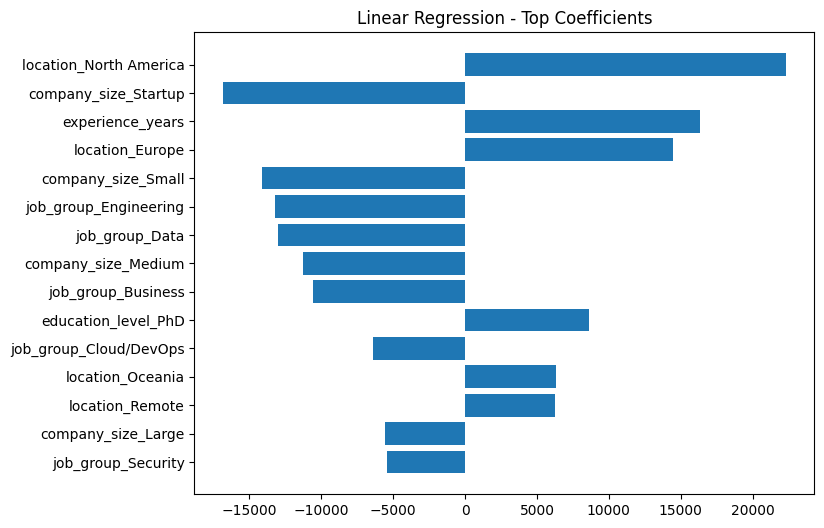

In [ ]:
coefficients = model.coef_
features = X.columns

# top 15 absolute coefficients
indices = np.argsort(np.abs(coefficients))[-15:]

plt.figure(figsize=(8,6))
plt.barh(range(len(indices)), coefficients[indices])
plt.yticks(range(len(indices)), [features[i] for i in indices])

plt.title("Linear Regression - Top Coefficients")
plt.show()

In [ ]:
#Evaluation metrics for this Regression
mse_lr = mean_squared_error(y_test, y_pred)
r2_lr = r2_score(y_test, y_pred)
rmse_lr = np.sqrt(mse_lr)

print("MSE :", int(mse_lr))
print("R2 :", np.round(r2_lr, decimals=3))
print("RMSE", int(rmse_lr))


MSE : 272035488
R2 : 0.804
RMSE 16493


####MSE: 272,035,488
This high value reflects large squared errors, meaning some predictions are significantly off. However, it is difficult to interpret directly due to the squared scale.

####RMSE: 16,493
On average, the model’s predictions differ from actual salaries by about 16k, which gives a clear sense of the typical error.

####R²: 0.804
The model explains 80.4% of the variance in salaries, indicating that it captures most of the underlying patterns.

###Overall feedback on linear regression
The model performs well overall: it explains a large part of salary variability, and the prediction error (~16k) is reasonable. Some variability remains unexplained, suggesting potential improvements with additional features or more complex models.

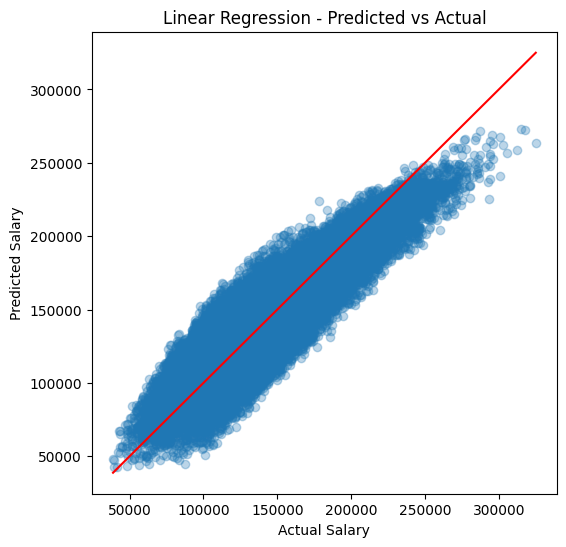

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Linear Regression - Predicted vs Actual")

#perfect prediction line
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red")

plt.show()

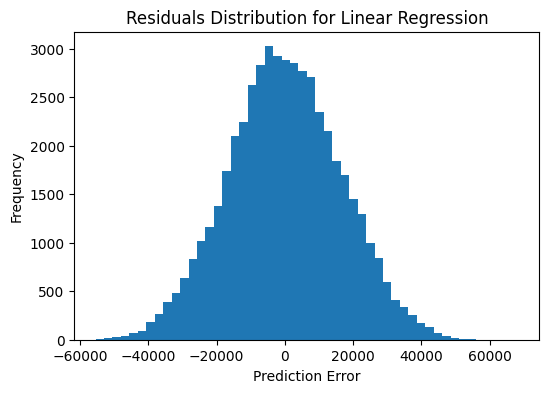

In [ ]:
residuals = y_test - y_pred

plt.figure(figsize=(6,4))
plt.hist(residuals, bins=50)

plt.title("Residuals Distribution for Linear Regression")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

##Ridge Regression

Ridge regression is an extension of linear regression that adds a regularization term to the model. While linear regression aims to minimize prediction error, Ridge also penalizes large coefficients.

This helps reduce overfitting, especially when features are correlated or numerous. Unlike linear regression, Ridge shrinks coefficients toward zero but does not eliminate them, leading to a more stable and generalizable model.


Alpha = 0.1
[ 16356.   4682.   2726. -10599.  -6436.]
Coef norm: 48736
Ridge MSE : 272035486
Ridge R2 : 0.8
Ridge RMSE : 16493

Alpha = 1
[ 16356.   4682.   2726. -10598.  -6436.]
Coef norm: 48735
Ridge MSE : 272035468
Ridge R2 : 0.8
Ridge RMSE : 16493

 
 


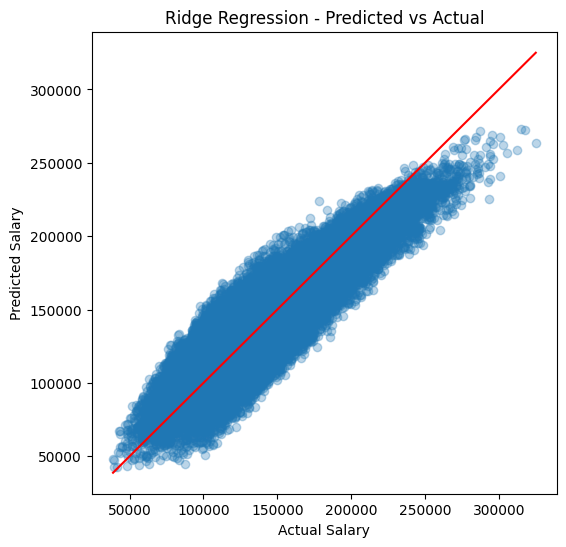

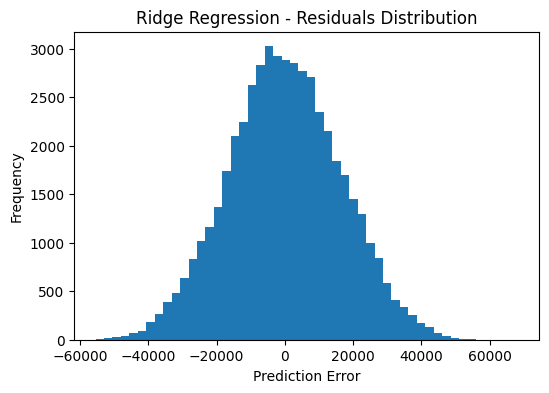


Alpha = 10
[ 16356.   4682.   2726. -10596.  -6434.]
Coef norm: 48728
Ridge MSE : 272035306
Ridge R2 : 0.8
Ridge RMSE : 16493

Alpha = 100
[ 16348.   4680.   2725. -10574.  -6413.]
Coef norm: 48656
Ridge MSE : 272035395
Ridge R2 : 0.8
Ridge RMSE : 16493

Alpha = 1000
[ 16276.   4660.   2713. -10353.  -6209.]
Coef norm: 47951
Ridge MSE : 272201167
Ridge R2 : 0.8
Ridge RMSE : 16498

Alpha = 10000
[15584.  4470.  2601. -8572. -4589.]
Coef norm: 42133
Ridge MSE : 285372478
Ridge R2 : 0.79
Ridge RMSE : 16892

Alpha = 50000
[13102.  3774.  2195. -4905. -1499.]
Coef norm: 29050
Ridge MSE : 402174276
Ridge R2 : 0.71
Ridge RMSE : 20054

Alpha = 100000
[10924.  3153.  1835. -3225.  -336.]
Coef norm: 22068
Ridge MSE : 526957558
Ridge R2 : 0.62
Ridge RMSE : 22955


In [ ]:
for alpha in [0.1, 1, 10, 100, 1000, 10000, 50000, 100000]:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)
    y_pred_ridge = ridge.predict(X_test)

    print(f"\nAlpha = {alpha}")
    print(np.round(ridge.coef_[:5]))  #5 first coefficients
    print("Coef norm:", int(np.linalg.norm(ridge.coef_)))


    mse_ridge = mean_squared_error(y_test, y_pred_ridge)
    r2_ridge = r2_score(y_test, y_pred_ridge)
    rmse_ridge = np.sqrt(mse_ridge)

    print("Ridge MSE :", int(mse_ridge))
    print("Ridge R2 :", np.round(r2_ridge, decimals=2))
    print("Ridge RMSE :", int(rmse_ridge))


    if alpha == 1 :
      print("\n \n ")
      plt.figure(figsize=(6,6))
      plt.scatter(y_test, y_pred_ridge, alpha=0.3)

      plt.xlabel("Actual Salary")
      plt.ylabel("Predicted Salary")
      plt.title("Ridge Regression - Predicted vs Actual")

      plt.plot([y_test.min(), y_test.max()],
              [y_test.min(), y_test.max()],
              color="red")

      plt.show()
      print("\n ")

      residuals_ridge = y_test - y_pred_ridge

      plt.figure(figsize=(6,4))
      plt.hist(residuals_ridge, bins=50)

      plt.title("Ridge Regression - Residuals Distribution")
      plt.xlabel("Prediction Error")
      plt.ylabel("Frequency")

      plt.show()

Ridge regression shows a very stable behavior across all values of alpha. Even when regularization increases significantly, the model maintains similar performance for small and moderate alpha values.

For low alpha values (0.1 → 100), performance remains almost identical to linear regression.
When alpha becomes very large (≥ 10,000), coefficients shrink significantly, leading to a clear drop in performance (R² decreases and RMSE increases).

 Ridge improves model stability but does not improve predictive performance in this dataset. It mainly confirms that the original linear regression was already well-conditioned and not strongly affected by multicollinearity.

##Lasso Regression

Lasso regression is an extension of linear regression that adds a regularization term with the ability to shrink coefficients and set some of them exactly to zero.

Like Ridge, it helps reduce overfitting by penalizing large coefficients. However, unlike Ridge, Lasso performs feature selection by removing less important variables entirely.

This makes Lasso useful for simplifying models and improving interpretability, especially when many features are not strongly relevant to the target variable.


Alpha = 0.1
[ 16356.   4682.   2726. -10598.  -6436.]
Coef norm: 48735
Lasso MSE : 272035432
Lasso R2 : 0.8043
Lasso RMSE : 16493

Alpha = 0.2
[ 16356.   4682.   2726. -10598.  -6435.]
Coef norm: 48733
Lasso MSE : 272035377
Lasso R2 : 0.8043
Lasso RMSE : 16493

Alpha = 0.5
[ 16356.   4682.   2725. -10596.  -6434.]
Coef norm: 48729
Lasso MSE : 272035224
Lasso R2 : 0.8043
Lasso RMSE : 16493

Alpha = 1
[ 16355.   4681.   2725. -10594.  -6431.]
Coef norm: 48722
Lasso MSE : 272035001
Lasso R2 : 0.8043
Lasso RMSE : 16493

 



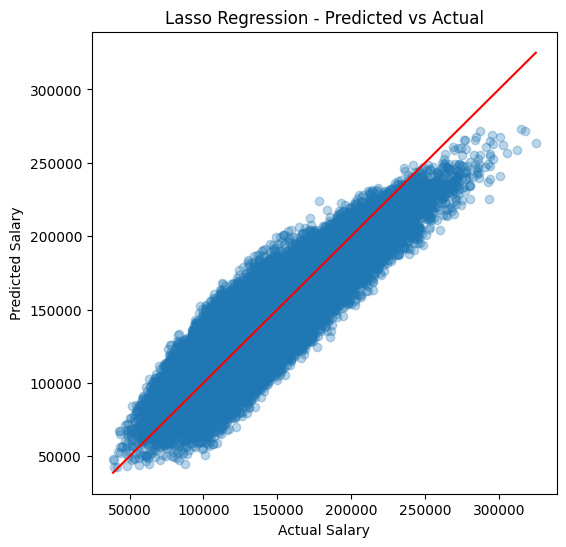

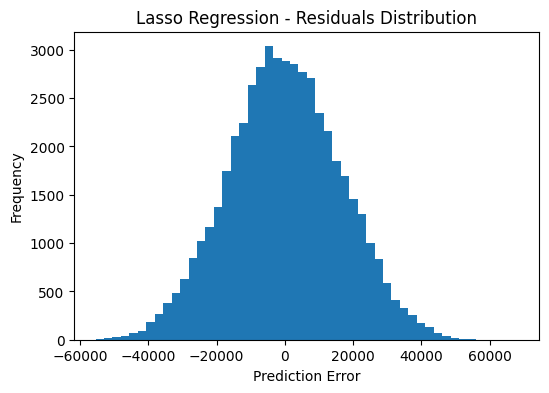




Alpha = 10
[ 16346.   4673.   2716. -10548.  -6386.]
Coef norm: 48599
Lasso MSE : 272034342
Lasso R2 : 0.8043
Lasso RMSE : 16493

Alpha = 100
[ 16257.   4584.   2626. -10101.  -5942.]
Coef norm: 47382
Lasso MSE : 272612634
Lasso R2 : 0.8039
Lasso RMSE : 16510

Alpha = 200
[16157.  4486.  2527. -9606. -5450.]
Coef norm: 46044
Lasso MSE : 274421409
Lasso R2 : 0.8026
Lasso RMSE : 16565

Alpha = 500
[15860.  4191.  2230. -8119. -3972.]
Coef norm: 42119
Lasso MSE : 287187639
Lasso R2 : 0.7934
Lasso RMSE : 16946

Alpha = 1000
[15364.  3699.  1735. -5641. -1509.]
Coef norm: 35977
Lasso MSE : 332915532
Lasso R2 : 0.7605
Lasso RMSE : 18245

Alpha = 10000
[6403.    0.    0.   -0.    0.]
Coef norm: 7771
Lasso MSE : 1116315395
Lasso R2 : 0.1968
Lasso RMSE : 33411

Alpha = 50000
[ 0.  0.  0. -0.  0.]
Coef norm: 0
Lasso MSE : 1389864055
Lasso R2 : -0.0
Lasso RMSE : 37280


In [ ]:
for alpha in [0.1, 0.2, 0.5,  1, 10, 100, 200, 500, 1000, 10000, 50000]:
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train, y_train)
    y_pred_lasso = lasso.predict(X_test)

    print(f"\nAlpha = {alpha}")
    print(np.round(lasso.coef_[:5]))  # 5 first coefficients
    print("Coef norm:", int(np.linalg.norm(lasso.coef_)))

    mse_lasso = mean_squared_error(y_test, y_pred_lasso)
    r2_lasso = r2_score(y_test, y_pred_lasso)
    rmse_lasso = np.sqrt(mse_lasso)

    print("Lasso MSE :", int(mse_lasso))
    print("Lasso R2 :", np.round(r2_lasso, decimals=4))
    print("Lasso RMSE :", int(rmse_lasso))

    if alpha == 1 :
      print('\n \n')
      y_pred_lasso = lasso.predict(X_test)

      plt.figure(figsize=(6,6))
      plt.scatter(y_test, y_pred_lasso, alpha=0.3)

      plt.xlabel("Actual Salary")
      plt.ylabel("Predicted Salary")
      plt.title("Lasso Regression - Predicted vs Actual")

      plt.plot([y_test.min(), y_test.max()],
              [y_test.min(), y_test.max()],
              color="red")

      plt.show()
      print('\n')

      residuals_lasso = y_test - y_pred_lasso

      plt.figure(figsize=(6,4))
      plt.hist(residuals_lasso, bins=50)

      plt.title("Lasso Regression - Residuals Distribution")
      plt.xlabel("Prediction Error")
      plt.ylabel("Frequency")

      plt.show()
      print('\n')

Lasso regression behaves similarly to linear regression for small alpha values, but becomes much more aggressive as alpha increases.

For low alpha values (0.1 → 10), performance is almost identical to linear regression.
As alpha increases, Lasso progressively removes features (coefficients shrink toward zero).
For very high alpha values (≥ 10,000), the model becomes too simple, resulting in a severe performance drop and underfitting (R² clearly collapses).

Lasso performs feature selection, but in this dataset it becomes too aggressive at high alpha values, removing too much information and degrading performance.

###Global Comparison — Linear vs Ridge vs Lasso

Compared to linear regression, both Ridge and Lasso do not significantly improve predictive performance for small alpha values. All three models achieve a similar R² around 0.80 and RMSE around 16.5k, showing that the baseline linear model is already strong.

Linear Regression: best baseline performance, simple and stable
Ridge: improves stability but does not significantly enhance accuracy
Lasso: useful for feature selection but becomes unstable with high regularization

The dataset is well-suited for linear modeling, and regularization mainly affects coefficient behavior rather than predictive performance. More complex models would be needed to improve accuracy further.

##Tree Regression Models

We are now using tree-based models such as Random Forest. Unlike linear models, we do not need the drop_first=True argument because tree algorithms are not affected by multicollinearity or the dummy variable trap. They split on feature values independently and do not assume linear relationships between variables.

Also, we do not need to scale the features for tree-based models. Unlike linear models, decision trees are not sensitive to the magnitude of variables, since they make splits based on thresholds rather than distances or dot products.

In [3]:
df_encoded_2 = pd.get_dummies(df_salary) #drop_first=False because Tree Models

# Features / target
X = df_encoded_2.drop("salary", axis=1)
y = df_encoded_2["salary"]

# Train / test split (NO SCALING)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

##Decision Tree Regression

A Decision Tree is the simplest tree-based model. It splits the data recursively based on feature thresholds to minimize prediction error. Unlike linear models, it can capture non-linear relationships.

However, a single decision tree tends to overfit — it memorizes the training data too well and generalizes poorly on new data. This is precisely why Random Forest was introduced: it averages many trees to reduce this variance.

Like other tree-based models, no scaling is needed.

In [4]:
# Model
dt = DecisionTreeRegressor(
    max_depth=10,        # limite la profondeur pour éviter l'overfitting
    random_state=42
)

# Training
dt.fit(X_train, y_train)

# Prediction
y_pred_dt = dt.predict(X_test)

# Feature importance
importances_dt = dt.feature_importances_
features = X.columns

for feature, imp in sorted(zip(features, importances_dt), key=lambda x: x[1], reverse=True)[:10]:
    print(f"{feature}: {imp:.4f}")

experience_years: 0.2427
location_North America: 0.1947
company_size_Enterprise: 0.1375
location_Asia: 0.0993
job_group_AI/ML: 0.0986
education_level_PhD: 0.0793
company_size_Large: 0.0660
education_level_Master: 0.0378
job_group_Cloud/DevOps: 0.0133
company_size_Medium: 0.0103


In [5]:
# Evaluation
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)

print("Decision Tree MSE:", int(mse_dt))
print("Decision Tree R2:", np.round(r2_dt, decimals=4))
print("Decision Tree RMSE:", int(rmse_dt))

Decision Tree MSE: 350485301
Decision Tree R2: 0.7478
Decision Tree RMSE: 18721


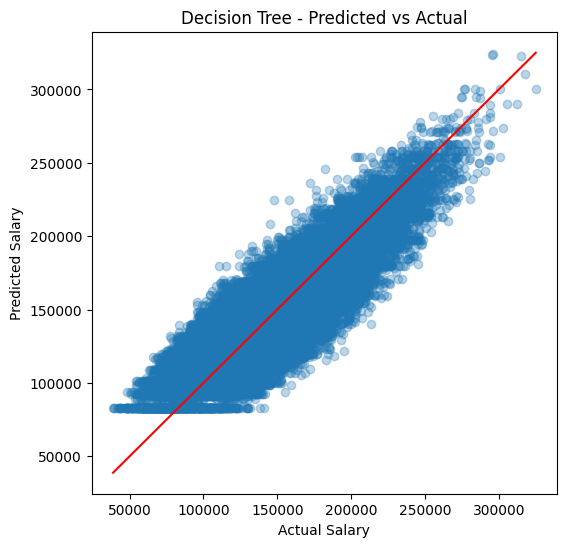

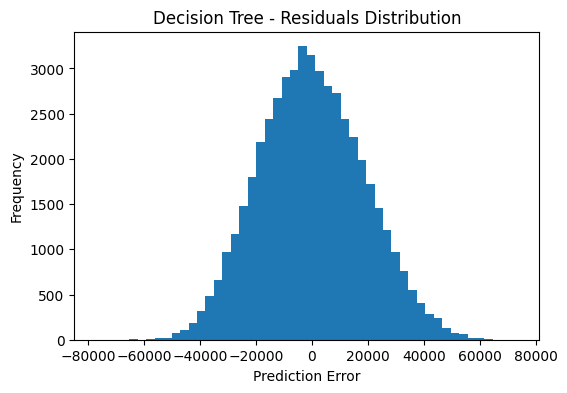

In [6]:
# Predicted vs Actual
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_dt, alpha=0.3)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Decision Tree - Predicted vs Actual")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red")
plt.show()

# Residuals
residuals_dt = y_test - y_pred_dt
plt.figure(figsize=(6,4))
plt.hist(residuals_dt, bins=50)
plt.title("Decision Tree - Residuals Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.show()

####MSE: 350,485,301 | R²: 0.7478 | RMSE: 18,721

The Decision Tree performs significantly worse than all other models tested so far.
With an R² of only 0.748 and an RMSE of ~18.7k, it clearly underperforms compared to
linear regression (R² ~0.804, RMSE ~16.5k) and will be even further outclassed by
ensemble methods.

This confirms a well-known limitation of single decision trees: **overfitting**.
The model memorizes training patterns too aggressively and fails to generalize well
on unseen data.

For this reason, **the Decision Tree will not be included in the final model comparison**.
It serves here only as a baseline to justify the use of more robust ensemble approaches
such as Random Forest and XGBoost, which address this variance problem by aggregating
multiple trees.

##Random Forest Regression

Random Forest is a non-linear ensemble model based on decision trees. Unlike linear models, it does not assume a linear relationship between features and the target variable.

It works by training multiple decision trees on random subsets of the data and averaging their predictions. This helps reduce overfitting and usually improves predictive performance compared to simple linear models.

Unlike previous models, scaling is unecessary here so we will use the original dataset

In [ ]:
# Model
rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Training
rf.fit(X_train, y_train)

# Prediction
y_pred_rf = rf.predict(X_test)

importances = rf.feature_importances_
features = X.columns

for feature, imp in sorted(zip(features, importances), key=lambda x: x[1], reverse=True):
    print(f"{feature}: {imp:.4f}")


experience_years: 0.2146
location_North America: 0.1484
company_size_Enterprise: 0.1050
location_Asia: 0.0758
job_group_AI/ML: 0.0753
education_level_PhD: 0.0605
skills_count: 0.0546
company_size_Large: 0.0503
certifications: 0.0294
education_level_Master: 0.0288
job_group_Cloud/DevOps: 0.0149
company_size_Medium: 0.0086
remote_work_Yes: 0.0085
location_Europe: 0.0076
job_group_Data: 0.0072
job_group_Business: 0.0069
job_group_Security: 0.0069
company_size_Startup: 0.0063
education_level_High School: 0.0059
remote_work_Hybrid: 0.0059
remote_work_No: 0.0058
job_group_Engineering: 0.0058
industry_Government: 0.0056
industry_Finance: 0.0056
industry_Healthcare: 0.0055
industry_Retail: 0.0055
industry_Consulting: 0.0055
industry_Media: 0.0055
industry_Education: 0.0055
education_level_Bachelor: 0.0055
industry_Technology: 0.0055
industry_Manufacturing: 0.0055
industry_Telecom: 0.0054
education_level_Diploma: 0.0025
company_size_Small: 0.0025
location_Remote: 0.0008
location_Oceania: 0.0008

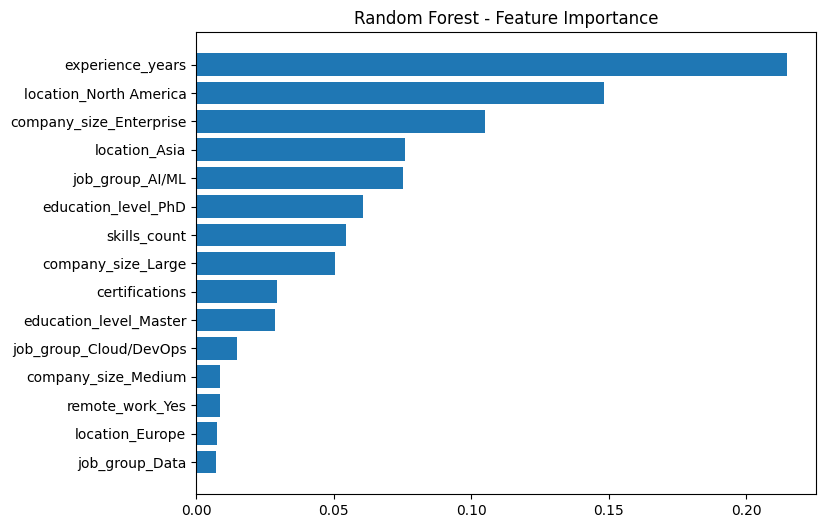

In [ ]:
importances = rf.feature_importances_
features = X.columns

indices = np.argsort(importances)[-15:]

plt.figure(figsize=(8,6))
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), [features[i] for i in indices])

plt.title("Random Forest - Feature Importance")
plt.show()

In [ ]:
# Evaluation
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)

print("Random Forest MSE:", int(mse_rf))
print("Random Forest R2:", np.round(r2_rf,decimals=4))
print("Random Forest RMSE:", int(rmse_rf))

Random Forest MSE: 286533560
Random Forest R2: 0.7938
Random Forest RMSE: 16927


The Random Forest model achieves a solid performance with an R² of 0.794, explaining around 79% of the variance in salaries.
However, its performance is slightly below the linear regression model.
The RMSE of approximately 16.9k indicates a moderate prediction error.
Overall, the model performs well but does not improve over simpler linear approaches on this dataset.

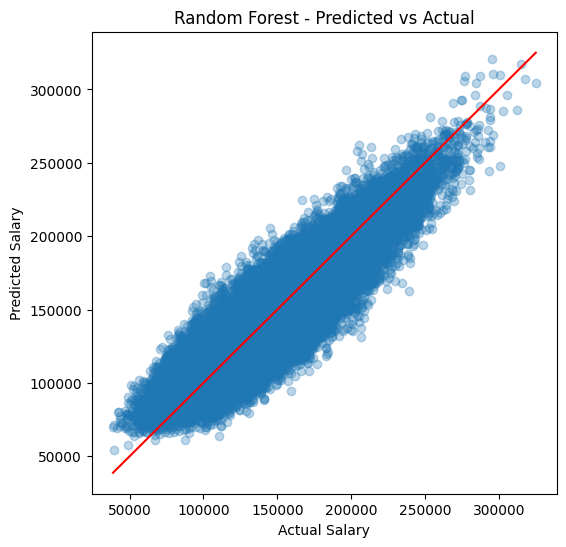

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_rf, alpha=0.3)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Random Forest - Predicted vs Actual")

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red")

plt.show()

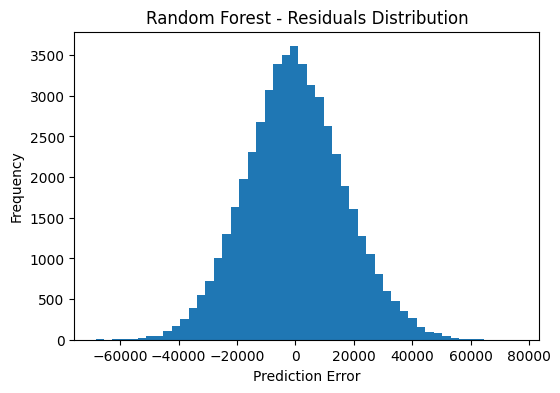

In [ ]:
residuals_rf = y_test - y_pred_rf

plt.figure(figsize=(6,4))
plt.hist(residuals_rf, bins=50)

plt.title("Random Forest - Residuals Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

##XGBoost regression model

XGBoost is a powerful non-linear ensemble model based on gradient boosting of decision trees. Unlike linear models, it does not assume a linear relationship between features and the target variable.

It builds trees sequentially, where each new tree learns to correct the errors made by the previous ones. This iterative learning process often leads to very high predictive performance.

Like other tree-based models, scaling is not necessary, so we use the original dataset without normalization.


In [ ]:
# Model
xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.04,
    random_state=42,
    n_jobs=-1
)

# Training
xgb.fit(X_train, y_train)

# Prediction
y_pred_xgb = xgb.predict(X_test)

# Feature importance
importances = xgb.feature_importances_
features = X.columns

for feature, imp in sorted(zip(features, importances), key=lambda x: x[1], reverse=True):
    print(f"{feature}: {imp:.4f}")

location_North America: 0.2753
company_size_Enterprise: 0.1261
company_size_Large: 0.0729
location_Asia: 0.0712
location_Europe: 0.0648
job_group_AI/ML: 0.0627
experience_years: 0.0607
education_level_PhD: 0.0457
company_size_Startup: 0.0381
education_level_High School: 0.0275
education_level_Master: 0.0257
education_level_Diploma: 0.0234
company_size_Small: 0.0200
job_group_Cloud/DevOps: 0.0178
job_group_Engineering: 0.0165
job_group_Data: 0.0119
remote_work_Yes: 0.0082
job_group_Business: 0.0063
job_group_Security: 0.0062
skills_count: 0.0057
certifications: 0.0036
education_level_Bachelor: 0.0031
company_size_Medium: 0.0025
industry_Government: 0.0003
industry_Telecom: 0.0003
industry_Retail: 0.0003
remote_work_Hybrid: 0.0003
industry_Technology: 0.0003
remote_work_No: 0.0003
industry_Healthcare: 0.0003
industry_Media: 0.0003
industry_Consulting: 0.0003
industry_Manufacturing: 0.0003
industry_Finance: 0.0003
location_Remote: 0.0003
industry_Education: 0.0002
location_Oceania: 0.0002

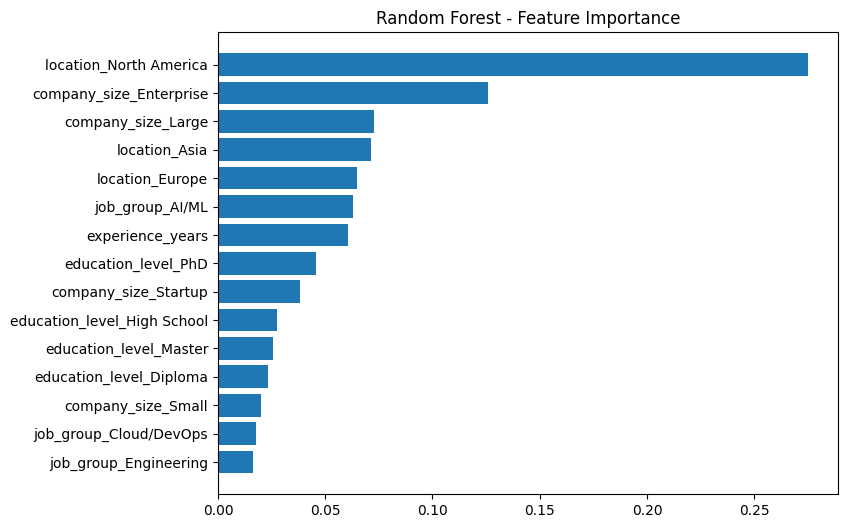

In [ ]:
indices = np.argsort(importances)[-15:]

plt.figure(figsize=(8,6))
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), [features[i] for i in indices])

plt.title("Random Forest - Feature Importance")
plt.show()

In [ ]:
# Evaluation
xg_mse = mean_squared_error(y_test, y_pred_xgb)
xg_r2 = r2_score(y_test, y_pred_xgb)
xg_rmse = np.sqrt(xg_mse)

print("XG Boost MSE:", int(xg_mse))
print("XG Boost R2:", np.round(xg_r2,decimals=4))
print("XG Boost RMSE:", int(xg_rmse))

XG Boost MSE: 256481232
XG Boost R2: 0.8155
XG Boost RMSE: 16015


The XGBoost model achieves the best performance among all tested models (we used number of estimators = 300), with an R² of 0.816, with an optimal Learning rate of 0.04 explaining over 81% of the variance in salaries.

Its RMSE of approximately 16.1k indicates a lower average prediction error compared to both linear regression and Random Forest.

The MSE is also the lowest, confirming improved overall accuracy.

Overall, XGBoost provides the strongest predictive performance on this dataset.

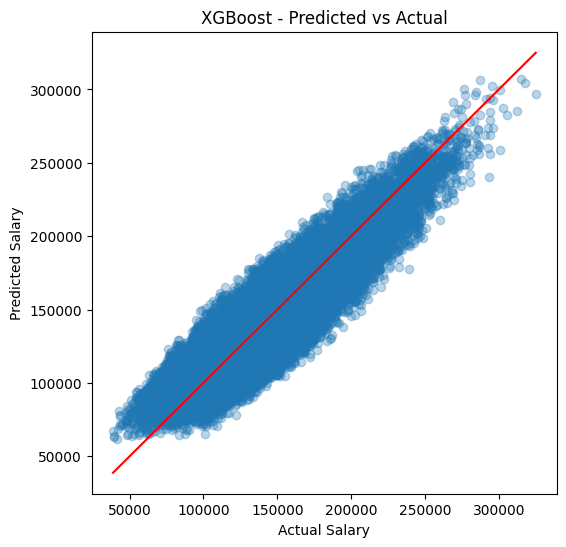

In [ ]:
y_pred_xgb = xgb.predict(X_test)

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_xgb, alpha=0.3)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("XGBoost - Predicted vs Actual")

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red")

plt.show()

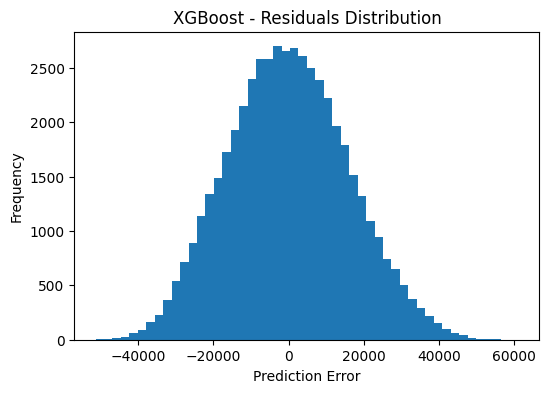

In [ ]:
residuals_xgb = y_test - y_pred_xgb

plt.figure(figsize=(6,4))
plt.hist(residuals_xgb, bins=50)

plt.title("XGBoost - Residuals Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

#Model Evaluation


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MSE": [
        272035488,
        272035468,
        272035001,
        286533560,
        256481232
    ],
    "RMSE": [
        16493,
        16493,
        16493,
        16927,
        16015
    ],
    "R2": [
        0.804,
        0.800,
        0.8043,
        0.7938,
        0.8155
    ]
})

# Sort by best model
results = results.sort_values(by="R2", ascending=False)
results = results.reset_index(drop=True)

results

,Model,MSE,RMSE,R2
0,XGBoost,256481232,16015,0.8155
1,Lasso Regression,272035001,16493,0.8043
2,Linear Regression,272035488,16493,0.8040
3,Ridge Regression,272035468,16493,0.8000
4,Random Forest,286533560,16927,0.7938


## Final Conclusion — Model Comparison

Overall, several models were tested to predict salary: linear regression, Ridge, Lasso, Random Forest, and XGBoost.

### Best model

XGBoost is the best performing model, achieving:

* Highest R² (~0.815)
* Lowest RMSE (~16.0k)

It slightly outperforms all other models, showing its ability to capture non-linear relationships and feature interactions.

---

### Linear vs tree-based models

* Linear models (Linear, Ridge, Lasso) perform very similarly
  → R² around 0.79–0.80
  → RMSE around 16.4k–17.2k

* Tree-based models (Random Forest, XGBoost) perform slightly better overall
  → XGBoost clearly outperforms Random Forest

However, the improvement over linear models is small, suggesting that the dataset is mostly linearly structured.

---

### What could be improved

#### Feature engineering

The main potential improvement likely comes from better feature design:

* interaction terms (experience × job group)
* non-linear transformations
* more domain-specific variables

#### Hyperparameter tuning

Models were not extensively optimized:

* XGBoost parameters (depth, learning rate, regularization)
* Random Forest parameters (tree depth, number of estimators)

Grid search or more advanced tuning methods could improve results.

#### One-Hot Encoding

OHE is appropriate in this case because categorical variables are not ordinal and models handle them well.

However:

* it increases dimensionality
* it can create sparsity
* it may not be optimal for high-cardinality variables

In this dataset, OHE is acceptable but not necessarily optimal in all cases.

---

### Final insight

The results indicate that:

* the dataset has a strong linear structure
* complex models provide only marginal improvements
* feature quality is more important than model complexity in this case

Improving data representation would likely lead to more gains than increasing model complexity.


In [ ]:
#used AI for this

#linear regression
linear = {
    "experience_years": 16356,
    "skills_count": 4682,
    "certifications": 2725,
    "job_group_Business": -10598,
    "job_group_Cloud/DevOps": -6436,
    "job_group_Data": -13019,
    "job_group_Engineering": -13198,
    "job_group_Security": -5405,
    "education_level_Diploma": -2086,
    "education_level_High School": -4283,
    "education_level_Master": 4354,
    "education_level_PhD": 8622,
    "industry_Education": 18,
    "industry_Finance": 78,
    "industry_Government": 41,
    "industry_Healthcare": 56,
    "industry_Manufacturing": -47,
    "industry_Media": 26,
    "industry_Retail": -93,
    "industry_Technology": 9,
    "industry_Telecom": -9,
    "company_size_Large": -5583,
    "company_size_Medium": -11246,
    "company_size_Small": -14122,
    "company_size_Startup": -16876,
    "location_Europe": 14471,
    "location_North America": 22334,
    "location_Oceania": 6307,
    "location_Remote": 6275,
    "remote_work_No": 35,
    "remote_work_Yes": 2515
}

#random_forest
rf = {
    "experience_years": 0.2146,
    "location_North America": 0.1484,
    "company_size_Enterprise": 0.1050,
    "location_Asia": 0.0758,
    "job_group_AI/ML": 0.0753,
    "education_level_PhD": 0.0605,
    "skills_count": 0.0546,
    "company_size_Large": 0.0503,
    "certifications": 0.0294,
    "education_level_Master": 0.0288,
    "job_group_Cloud/DevOps": 0.0149,
    "company_size_Medium": 0.0086,
    "remote_work_Yes": 0.0085,
    "location_Europe": 0.0076,
    "job_group_Data": 0.0072,
    "job_group_Business": 0.0069,
    "job_group_Security": 0.0069,
    "company_size_Startup": 0.0063,
    "education_level_High School": 0.0059,
    "remote_work_Hybrid": 0.0059,
    "remote_work_No": 0.0058,
    "job_group_Engineering": 0.0058,
    "industry_Government": 0.0056,
    "industry_Finance": 0.0056,
    "industry_Healthcare": 0.0055,
    "industry_Retail": 0.0055,
    "industry_Consulting": 0.0055,
    "industry_Media": 0.0055,
    "industry_Education": 0.0055,
    "education_level_Bachelor": 0.0055,
    "industry_Technology": 0.0055,
    "industry_Manufacturing": 0.0055,
    "industry_Telecom": 0.0054,
    "education_level_Diploma": 0.0025,
    "company_size_Small": 0.0025,
    "location_Remote": 0.0008,
    "location_Oceania": 0.0008
}

#xgboost
xgb = {
    "location_North America": 0.2753,
    "company_size_Enterprise": 0.1261,
    "company_size_Large": 0.0729,
    "location_Asia": 0.0712,
    "location_Europe": 0.0648,
    "job_group_AI/ML": 0.0627,
    "experience_years": 0.0607,
    "education_level_PhD": 0.0457,
    "company_size_Startup": 0.0381,
    "education_level_High School": 0.0275,
    "education_level_Master": 0.0257,
    "education_level_Diploma": 0.0234,
    "company_size_Small": 0.0200,
    "job_group_Cloud/DevOps": 0.0178,
    "job_group_Engineering": 0.0165,
    "job_group_Data": 0.0119,
    "remote_work_Yes": 0.0082,
    "job_group_Business": 0.0063,
    "job_group_Security": 0.0062,
    "skills_count": 0.0057,
    "certifications": 0.0036,
    "education_level_Bachelor": 0.0031,
    "company_size_Medium": 0.0025,
    "industry_Government": 0.0003,
    "industry_Telecom": 0.0003,
    "industry_Retail": 0.0003,
    "remote_work_Hybrid": 0.0003,
    "industry_Technology": 0.0003,
    "remote_work_No": 0.0003,
    "industry_Healthcare": 0.0003,
    "industry_Media": 0.0003,
    "industry_Consulting": 0.0003,
    "industry_Manufacturing": 0.0003,
    "industry_Finance": 0.0003,
    "location_Remote": 0.0003,
    "industry_Education": 0.0002,
    "location_Oceania": 0.0002
}

#merge
df = pd.DataFrame({
    "Feature": sorted(set(linear) | set(rf) | set(xgb))
})

df["Linear"] = df["Feature"].map(linear).fillna(0)
df["RandomForest"] = df["Feature"].map(rf).fillna(0)
df["XGBoost"] = df["Feature"].map(xgb).fillna(0)

df

,Feature,Linear,RandomForest,XGBoost
0,certifications,2725.0,0.0294,0.0036
1,company_size_Enterprise,0.0,0.1050,0.1261
2,company_size_Large,-5583.0,0.0503,0.0729
3,company_size_Medium,-11246.0,0.0086,0.0025
4,company_size_Small,-14122.0,0.0025,0.0200
5,company_size_Startup,-16876.0,0.0063,0.0381
6,education_level_Bachelor,0.0,0.0055,0.0031
7,education_level_Diploma,-2086.0,0.0025,0.0234
8,education_level_High School,-4283.0,0.0059,0.0275
9,education_level_Master,4354.0,0.0288,0.0257


In [ ]:
summary = pd.DataFrame({
    "Feature_Group": [
        "Experience",
        "Location",
        "Company Size",
        "Job Group",
        "Education",
        "Skills Count",
        "Certifications",
        "Industry",
        "Remote Work"
    ],
    "Linear_Impact": [
        "Very High",
        "Very High",
        "High (negative for small/startup)",
        "High",
        "Medium",
        "Medium",
        "Low",
        "Low",
        "Very Low"
    ],
    "RandomForest_Impact": [
        "Very High",
        "Very High",
        "High",
        "Medium",
        "Medium",
        "Medium",
        "Low",
        "Very Low",
        "Very Low"
    ],
    "XGBoost_Impact": [
        "High",
        "Very High",
        "High",
        "Medium-High",
        "Medium",
        "Low-Medium",
        "Low",
        "Very Low",
        "Very Low"
    ],
    "Interpretation": [
        "Main salary driver (strong across all models)",
        "Strong geographical effect (especially North America)",
        "Larger companies pay more",
        "AI/ML and Engineering roles are premium",
        "Higher education increases salary",
        "Secondary factor (less important in XGBoost)",
        "Weak predictor",
        "Almost no predictive power",
        "Negligible impact"
    ]
})

summary

,Feature_Group,Linear_Impact,RandomForest_Impact,XGBoost_Impact,Interpretation
0,Experience,Very High,Very High,High,Main salary driver (strong across all models)
1,Location,Very High,Very High,Very High,Strong geographical effect (especially North A...
2,Company Size,High (negative for small/startup),High,High,Larger companies pay more
3,Job Group,High,Medium,Medium-High,AI/ML and Engineering roles are premium
4,Education,Medium,Medium,Medium,Higher education increases salary
5,Skills Count,Medium,Medium,Low-Medium,Secondary factor (less important in XGBoost)
6,Certifications,Low,Low,Low,Weak predictor
7,Industry,Low,Very Low,Very Low,Almost no predictive power
8,Remote Work,Very Low,Very Low,Very Low,Negligible impact


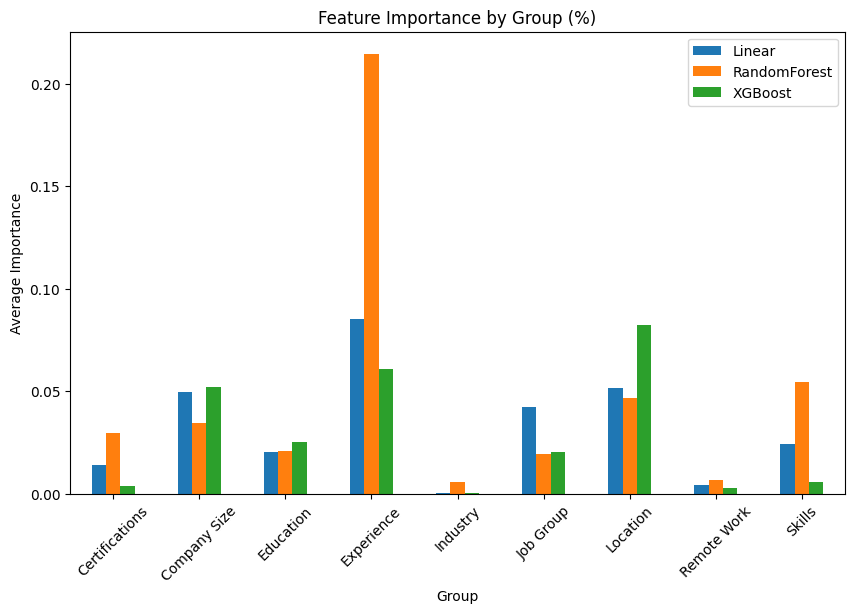

In [ ]:
# copy
df_grouped = df.copy()

#Normalize
df_grouped["Linear"] = np.abs(df_grouped["Linear"])
df_grouped["Linear"] = df_grouped["Linear"] / df_grouped["Linear"].sum()

df_grouped["RandomForest"] = df_grouped["RandomForest"] / df_grouped["RandomForest"].sum()
df_grouped["XGBoost"] = df_grouped["XGBoost"] / df_grouped["XGBoost"].sum()

#regroup columns
def get_group(feature):
    if "location" in feature:
        return "Location"
    elif "company_size" in feature:
        return "Company Size"
    elif "job_group" in feature:
        return "Job Group"
    elif "education_level" in feature:
        return "Education"
    elif "industry" in feature:
        return "Industry"
    elif "remote_work" in feature:
        return "Remote Work"
    elif "experience" in feature:
        return "Experience"
    elif "skills" in feature:
        return "Skills"
    elif "certifications" in feature:
        return "Certifications"
    else:
        return "Other"

df_grouped["Group"] = df_grouped["Feature"].apply(get_group)

#aggregte by mean
grouped = df_grouped.groupby("Group")[["Linear", "RandomForest", "XGBoost"]].mean()

#plot
grouped.plot(kind="bar", figsize=(10,6))

plt.title("Feature Importance by Group (%)")
plt.ylabel("Average Importance")
plt.xticks(rotation=45)

plt.show()


#Results Interpretation

### Best Model

XGBoost is the best performing model with the highest R² (0.8155) and the lowest RMSE (~16k). It slightly outperforms linear models and Random Forest, showing better ability to capture complex relationships in the data.


### Why this model performs best

XGBoost benefits from:

* A Sequential learning (boosting)
* A Better handling of non-linear relationships
* A Focus on reducing residual errors step by step

This enables it to outperform both linear models which is too simple and Random Forest which is less optimized. Random Forest was by far the longest to execute, it took 6 to 7 minutes !



### Key Drivers of Salary

Across all models, the most important variables are:

* **Location** (especially North America)
* **Company size**
* **Experience (years)**
* **Job group (AI/ML, Engineering)**
* **Skills**

Less important variables:

* Industry
* Remote work
* Certifications



### Model Reliability

The model is reasonably reliable:

* R² > 0.8 → strong explanatory power
* RMSE ≈ 16k → acceptable prediction error

However, some variability remains unexplained, suggesting that additional features or external factors could improve performance.

---

## Business Conclusion

### How companies can use this model

* Benchmark salaries based on location and company size
* Adjust compensation strategies for competitive roles (AI/ML, Engineering)
* Improve hiring strategies by understanding key salary drivers



### Limitations

* Some important factors are of course missing to have a more accurate prediction (e.g., company reputation, individual performance)
* One-hot encoding may reduce interpretability
* Model may not generalize perfectly to unseen markets



### Recommendations

* Collect more granular data (e.g., seniority levels, company revenue)
* Test additional models or tuning
* Of course, you have to se this model as a **decision-support tool**, not as an absolute predictor. Salary relies on numerous other factors

---

## Other eventual improvments


To further improve the project:

* Perform **hyperparameter tuning** (GridSearch / RandomSearch)
* Use **cross-validation** for more robust evaluation
* Build a clean **sklearn pipeline**
* Improve **feature engineering**
* Create more advanced **visualizations (heatmaps, comparisons)**
* Strengthen **storytelling and business insights**
